## 1. loading and cleaning my data
just loading the raw file here and checking it looks okay before i start cleaning anything

In [1]:
# loading the raw edgeiiot dataset before any cleaning
import pandas as pd

In [2]:
df = pd.read_csv("ML-EdgeIIoT-dataset.csv")

C:\Users\user\AppData\Local\Temp\ipykernel_24460\3196203159.py:1: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.uri.query, 4: http.request.method, 5: http.referer, 6: http.request.full_uri, 7: http.request.version, 8: tcp.options, 9: tcp.payload, 10: tcp.srcport, 11: dns.qry.name.len, 12: mqtt.conack.flags, 13: mqtt.msg, 14: mqtt.protoname, 15: mqtt.topic) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("ML-EdgeIIoT-dataset.csv")


In [3]:
df.shape

(157800, 63)

In [4]:
df.head()

,frame.time,ip.src_host,ip.dst_host,arp.dst.proto_ipv4,arp.opcode,arp.hw.size,arp.src.proto_ipv4,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,...,mqtt.proto_len,mqtt.protoname,mqtt.topic,mqtt.topic_len,mqtt.ver,mbtcp.len,mbtcp.trans_id,mbtcp.unit_id,Attack_label,Attack_type
0,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
1,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
2,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
3,6.0,192.168.0.101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM
4,6.0,192.168.0.152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,MITM


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 157800 entries, 0 to 157799
Data columns (total 63 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   frame.time                 157800 non-null  str    
 1   ip.src_host                157800 non-null  str    
 2   ip.dst_host                157800 non-null  str    
 3   arp.dst.proto_ipv4         157800 non-null  object 
 4   arp.opcode                 157800 non-null  float64
 5   arp.hw.size                157800 non-null  float64
 6   arp.src.proto_ipv4         157800 non-null  object 
 7   icmp.checksum              157800 non-null  float64
 8   icmp.seq_le                157800 non-null  float64
 9   icmp.transmit_timestamp    157800 non-null  float64
 10  icmp.unused                157800 non-null  float64
 11  http.file_data             157800 non-null  object 
 12  http.content_length        157800 non-null  float64
 13  http.request.uri.query     157800 non-nu

In [6]:
# I WAS REMOVING DUPLICATE ROWS BEFORE DOING ANYTHING ELSE
df.duplicated().sum()

np.int64(814)

In [7]:
df = df.drop_duplicates()

In [8]:
df.shape

(156986, 63)

## 2. feature selection
going through the columns one by one, dropping the ones that dont look useful to me

In [9]:
df.columns[df.nunique() == 1]

Index(['icmp.unused', 'http.tls_port', 'dns.qry.type',
       'dns.retransmit_request_in', 'mqtt.msg_decoded_as', 'mbtcp.len',
       'mbtcp.trans_id', 'mbtcp.unit_id'],
      dtype='str')

In [10]:
df = df.drop(columns=['icmp.unused', 'http.tls_port', 'dns.qry.type', 'dns.retransmit_request_in', 'mqtt.msg_decoded_as', 'mbtcp.len', 'mbtcp.trans_id', 'mbtcp.unit_id'])

In [11]:
df.shape

(156986, 55)

In [12]:
df.isnull().sum().sum()

np.int64(0)

In [13]:
(df.select_dtypes(include='number') == float('inf')).sum().sum()

np.int64(0)

In [14]:
df.iloc[:, 0].apply(type).value_counts()

frame.time
<class 'str'>    156986
Name: count, dtype: int64

In [15]:
df["arp.dst.proto_ipv4"].apply(type).value_counts()

arp.dst.proto_ipv4
<class 'str'>    130258
<class 'int'>     26728
Name: count, dtype: int64

In [16]:
df["arp.dst.proto_ipv4"].unique()[:10]

array(['0.0', '0', '192.168.0.128', '192.168.0.170', '192.168.0.1',
       '192.168.0.101', 0, '192.168.0.147', '192.168.0.129'], dtype=object)

In [17]:
# making every value in this column consistent by converting the whole column to text
df["arp.dst.proto_ipv4"] = df["arp.dst.proto_ipv4"].astype(str)

In [18]:
df["arp.dst.proto_ipv4"].apply(type).value_counts()

arp.dst.proto_ipv4
<class 'str'>    156986
Name: count, dtype: int64

In [19]:
df.describe()

,arp.opcode,arp.hw.size,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,http.content_length,http.response,tcp.ack,tcp.ack_raw,tcp.checksum,...,dns.retransmit_request,mqtt.conflag.cleansess,mqtt.conflags,mqtt.hdrflags,mqtt.len,mqtt.msgtype,mqtt.proto_len,mqtt.topic_len,mqtt.ver,Attack_label
count,156986.000000,156986.000000,156986.000000,156986.000000,1.569860e+05,156986.000000,156986.000000,1.569860e+05,1.569860e+05,156986.000000,...,156986.000000,156986.000000,156986.000000,156986.000000,156986.000000,156986.000000,156986.000000,156986.000000,156986.000000,156986.000000
mean,0.014269,0.060158,3063.092582,3256.779643,4.067800e+04,14.791822,0.045985,7.197165e+07,1.365391e+09,25930.359064,...,0.000006,0.007962,0.015925,2.594677,0.421515,0.162167,0.031850,0.190488,0.031850,0.845203
std,0.150167,0.597773,11171.017595,11433.213688,1.768640e+06,230.251867,0.209453,3.108831e+08,1.295170e+09,21488.178373,...,0.002524,0.088877,0.177754,20.747991,3.615805,1.296749,0.355508,2.129663,0.355508,0.361712
min,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000e+00,3333.250000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,1.000000e+00,1.173613e+09,24112.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,4.790000e+02,2.372259e+09,44820.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,2.000000,6.000000,65532.000000,65524.000000,7.728902e+07,83655.000000,1.000000,2.147333e+09,4.294947e+09,65535.000000,...,1.000000,1.000000,2.000000,224.000000,39.000000,14.000000,4.000000,24.000000,4.000000,1.000000


In [20]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
arp.opcode,156986.0,1.426879e-02,1.501671e-01,0.0,0.00,0.000000e+00,0.000000e+00,2.000000e+00
arp.hw.size,156986.0,6.015823e-02,5.977731e-01,0.0,0.00,0.000000e+00,0.000000e+00,6.000000e+00
icmp.checksum,156986.0,3.063093e+03,1.117102e+04,0.0,0.00,0.000000e+00,0.000000e+00,6.553200e+04
icmp.seq_le,156986.0,3.256780e+03,1.143321e+04,0.0,0.00,0.000000e+00,0.000000e+00,6.552400e+04
icmp.transmit_timestamp,156986.0,4.067800e+04,1.768640e+06,0.0,0.00,0.000000e+00,0.000000e+00,7.728902e+07
http.content_length,156986.0,1.479182e+01,2.302519e+02,0.0,0.00,0.000000e+00,0.000000e+00,8.365500e+04
http.response,156986.0,4.598499e-02,2.094532e-01,0.0,0.00,0.000000e+00,0.000000e+00,1.000000e+00
tcp.ack,156986.0,7.197165e+07,3.108831e+08,0.0,0.00,1.000000e+00,4.790000e+02,2.147333e+09
tcp.ack_raw,156986.0,1.365391e+09,1.295170e+09,0.0,0.00,1.173613e+09,2.372259e+09,4.294947e+09
tcp.checksum,156986.0,2.593036e+04,2.148818e+04,0.0,3333.25,2.411200e+04,4.482000e+04,6.553500e+04


In [21]:
df.to_csv("ML-EdgeIIoT-cleaned.csv", index=False)

In [22]:
# checking the attack types again after cleaning to see if the numbers changed
df["Attack_type"].value_counts()

Attack_type
Normal                   24301
DDoS_UDP                 14498
DDoS_ICMP                14090
Ransomware               10925
DDoS_HTTP                10561
SQL_injection            10311
Uploading                10269
DDoS_TCP                 10247
Backdoor                 10195
Vulnerability_scanner    10076
Port_Scanning            10071
XSS                      10052
Password                  9989
Fingerprinting            1001
MITM                       400
Name: count, dtype: int64

In [23]:
# checking if all the removed duplicates were MITM rows
1214 - 400 == 814

True

In [24]:
import matplotlib.pyplot as plt

Text(0.5, 0, 'Type of Attack')

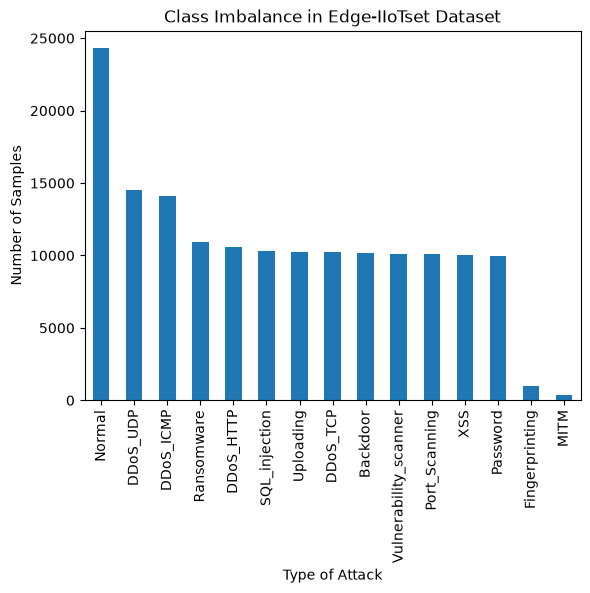

In [25]:
df["Attack_type"].value_counts().plot(kind="bar")
plt.title("Class Imbalance in Edge-IIoTset Dataset")
plt.ylabel("Number of Samples")
plt.xlabel("Type of Attack")

In [26]:
df["Attack_label"].value_counts()

Attack_label
1    132685
0     24301
Name: count, dtype: int64

In [27]:
# checking how many unique values each text column has before deciding what to do with them
df.select_dtypes(include='object').nunique()

C:\Users\user\AppData\Local\Temp\ipykernel_24460\4069193328.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').nunique()


frame.time                155186
ip.src_host                19090
ip.dst_host                 8084
arp.dst.proto_ipv4             8
arp.src.proto_ipv4             9
http.file_data               497
http.request.uri.query      1666
http.request.method            7
http.referer                   5
http.request.full_uri       4074
http.request.version           9
tcp.options                73140
tcp.payload                27370
tcp.srcport                33551
dns.qry.name.len               9
mqtt.conack.flags              4
mqtt.msg                     118
mqtt.protoname                 4
mqtt.topic                     4
Attack_type                   15
dtype: int64

In [28]:
df.columns

Index(['frame.time', 'ip.src_host', 'ip.dst_host', 'arp.dst.proto_ipv4',
       'arp.opcode', 'arp.hw.size', 'arp.src.proto_ipv4', 'icmp.checksum',
       'icmp.seq_le', 'icmp.transmit_timestamp', 'http.file_data',
       'http.content_length', 'http.request.uri.query', 'http.request.method',
       'http.referer', 'http.request.full_uri', 'http.request.version',
       'http.response', 'tcp.ack', 'tcp.ack_raw', 'tcp.checksum',
       'tcp.connection.fin', 'tcp.connection.rst', 'tcp.connection.syn',
       'tcp.connection.synack', 'tcp.dstport', 'tcp.flags', 'tcp.flags.ack',
       'tcp.len', 'tcp.options', 'tcp.payload', 'tcp.seq', 'tcp.srcport',
       'udp.port', 'udp.stream', 'udp.time_delta', 'dns.qry.name',
       'dns.qry.name.len', 'dns.qry.qu', 'dns.retransmission',
       'dns.retransmit_request', 'mqtt.conack.flags', 'mqtt.conflag.cleansess',
       'mqtt.conflags', 'mqtt.hdrflags', 'mqtt.len', 'mqtt.msg',
       'mqtt.msgtype', 'mqtt.proto_len', 'mqtt.protoname', 'mqtt.topi

In [29]:
# checking if MITM attacks are more likely to use ARP, since MITM often involves ARP spoofing
df[df["arp.dst.proto_ipv4"] != "0.0"]["Attack_type"].value_counts()

Attack_type
Normal                   24301
DDoS_UDP                 14498
DDoS_ICMP                14090
Ransomware               10925
DDoS_HTTP                10561
SQL_injection            10311
Uploading                10269
DDoS_TCP                 10247
Backdoor                 10195
Vulnerability_scanner    10076
Port_Scanning            10071
XSS                      10052
Password                  9989
Fingerprinting            1001
Name: count, dtype: int64

In [30]:
df[~df["arp.dst.proto_ipv4"].isin(["0", "0.0"])]["Attack_type"].value_counts()

Attack_type
DDoS_UDP                 1402
Port_Scanning             772
Ransomware                505
Backdoor                  126
Fingerprinting             82
Normal                     42
XSS                        33
Password                    5
Vulnerability_scanner       5
SQL_injection               3
Uploading                   1
Name: count, dtype: int64

In [31]:
df["frame.time"].head()

0     6.0
1     6.0
8     0.0
29    0.0
30    0.0
Name: frame.time, dtype: str

In [32]:
# looking at more rows to understand why frame.time looks so repetitive
df["frame.time"].sample(10)

10729      2021 23:55:55.543667000 
133117                192.168.0.128
14261      2021 23:09:38.477626000 
3669       2021 16:22:27.773108000 
148003     2021 23:19:50.578753000 
38410      2021 11:37:17.013815000 
123075     2021 21:53:04.828136000 
66155      2021 16:30:15.297987000 
124299     2021 16:21:11.841002000 
62451      2021 19:57:38.455944000 
Name: frame.time, dtype: str

In [33]:
# frame.time is basically a timestamp ID so its not useful as a feature
df = df.drop(columns=["frame.time"])

In [34]:
df.shape

(156986, 54)

In [35]:
# looking at the actual IP addresses in this column
df["ip.src_host"].sample(10)

44179      192.168.0.128
106075     192.168.0.128
151441    21.182.120.107
58395      192.168.0.128
149260     43.77.209.222
78268      192.168.0.170
125806     192.168.0.128
3677                   0
77529      192.168.0.170
112775                 0
Name: ip.src_host, dtype: str

In [36]:
# dropping both IP address columns since they wont generalize to new traffic
df = df.drop(columns=["ip.src_host", "ip.dst_host"])

In [37]:
df.shape

(156986, 52)

In [38]:
# checking real values in tcp.payload before deciding 
df["tcp.payload"].sample(10)

93541                                                     0
94067                                                     0
65072                                                   0.0
14424                                                     0
51905                                                     0
99418     485454502f312e3120343034204e6f7420466f756e640d...
144326                                                  0.0
93498                                                     0
145182                                                  0.0
33742                                                     0
Name: tcp.payload, dtype: object

In [39]:
# dropping tcp.payload since its raw hex data thats basically unique per row
df = df.drop(columns=["tcp.payload"])

In [40]:
df.shape

(156986, 51)

In [41]:
# checking real values in tcp.options before deciding to drop it
df["tcp.options"].sample(10)

128907                           0
62886     0101080a7b81f2eae80d0627
55478     0101080a7ad74c53e7625535
141697                         0.0
60726     0101080a7b5173bfe7dc822c
88976     0101080a2b1448ee3d7e56d3
52964                          0.0
89498     0101080a3dd9222c2b6f1177
103560    0101080a9e40132b9ab28042
12997     0101080a8edf4855c6022c40
Name: tcp.options, dtype: object

In [42]:
# i am removing tcp.options because it wont help the model generalize
df = df.drop(columns=["tcp.options"])

In [43]:
df.shape

(156986, 50)

In [44]:
df["tcp.srcport"].sample(10)

9744          0.0
97250        80.0
153674        0.0
155711        0.0
129789        0.0
117227     1883.0
13387     45558.0
84323        80.0
38733        80.0
95009        80.0
Name: tcp.srcport, dtype: object

# investigating whether tcp.srcport is worth keeping in some form
(df["tcp.srcport"].astype(float) < 1024).sum()
This step failed because tcp.srcport had inconsistent data (a hostname instead of a numeric port)this finding supported removing the column.

In [45]:
# dropping tcp.srcport because it contains inconsistent values like a hostname instead of a port number
df = df.drop(columns=["tcp.srcport"])

In [46]:
df.shape

(156986, 49)

In [47]:
# saving progress after feature selection so far
df.to_csv("ML-EdgeIIoT-featureselected.csv", index=False)

In [48]:
# rechecking unique values in the remaining text columns now that the worst ones are gone
df.select_dtypes(include='object').nunique()

C:\Users\user\AppData\Local\Temp\ipykernel_24460\647437961.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').nunique()


arp.dst.proto_ipv4           8
arp.src.proto_ipv4           9
http.file_data             497
http.request.uri.query    1666
http.request.method          7
http.referer                 5
http.request.full_uri     4074
http.request.version         9
dns.qry.name.len             9
mqtt.conack.flags            4
mqtt.msg                   118
mqtt.protoname               4
mqtt.topic                   4
Attack_type                 15
dtype: int64

In [49]:
# I want to checking real values in http.request.full_uri before deciding what to do
df["http.request.full_uri"].sample(10)

64911                                                   0.0
1225                                                    0.0
144302                                                  0.0
13414     http://192.168.0.128/DVWA/hackable/uploads/hac...
139578                                                  0.0
60695                                                     0
130497                                                  0.0
2497                                                    0.0
70935                                                   0.0
10643                                                   0.0
Name: http.request.full_uri, dtype: object

In [50]:
# dropping http.request.full_uri since it contains specific IPs and paths like the columns we already removed
df = df.drop(columns=["http.request.full_uri"])

In [51]:
df.shape

(156986, 48)

In [52]:
df["http.request.uri.query"].sample(10)

65455                                           0.0
141136                                          0.0
67769                                           0.0
30022                                             0
124737                                          0.0
53349                                           0.0
27826                                             0
84655     supa[db_path]=http://cirt.net/rfiinc.txt?
124831                                          0.0
140349                                          0.0
Name: http.request.uri.query, dtype: object

In [53]:
(df["http.request.uri.query"] != "0.0").sum()

np.int64(111837)

In [54]:
# i am redoing this count properly since I made the same mistake as before
(~df["http.request.uri.query"].isin(["0", "0.0"])).sum()

np.int64(94201)

In [55]:
df[~df["http.request.uri.query"].isin(["0", "0.0"])]["http.request.uri.query"].sample(10)

4071                                                0.0
10807                                               0.0
101466                                              0.0
127778                                              0.0
9727                                                0.0
146221                                              0.0
125097                                              0.0
135126                                              0.0
122703                                              0.0
78147     CONFIG[main_path]=http://cirt.net/rfiinc.txt?
Name: http.request.uri.query, dtype: object

In [56]:
# checking the actual data types inside this column to explain the confusing result
df["http.request.uri.query"].apply(type).value_counts()

http.request.uri.query
<class 'float'>    91450
<class 'str'>      65536
Name: count, dtype: int64

In [57]:
# fixing the check properly this time to catch both string and float placeholders
(~df["http.request.uri.query"].astype(str).isin(["0", "0.0"])).sum()

np.int64(2751)

In [58]:
# dropping http.request.uri.query since its over 98% placeholder values with barely any real data
df = df.drop(columns=["http.request.uri.query"])

In [59]:
df.shape

(156986, 47)

In [60]:
# saving progress after finishing feature selection and confirming everything with run all
df.to_csv("ML-EdgeIIoT-featureselected-final.csv", index=False)

In [61]:
df["mqtt.msg"].sample(10)

116955                             0
90316                            0.0
50651                            0.0
143479                           0.0
139854                           0.0
90296                            0.0
123114    32342e31352037352e34360d0a
15321                            0.0
52668                            0.0
86170                            0.0
Name: mqtt.msg, dtype: object

In [62]:
(~df["mqtt.msg"].astype(str).isin(["0", "0.0"])).sum()

np.int64(1246)

In [63]:
df[~df["mqtt.msg"].astype(str).isin(["0", "0.0"])]["mqtt.msg"].sample(10)

106290    32332e36352037342e35380d0a
117948    32342e33332037352e37390d0a
126632    32332e38342037342e39320d0a
123574    32342e35352037362e31390d0a
105602    32342e30342037352e32380d0a
123607    32342e35352037362e31390d0a
121723    32342e31342037352e34350d0a
126115    32332e36332037342e35330d0a
118378    32322e36382037322e38330d0a
105314    32332e39362037352e31330d0a
Name: mqtt.msg, dtype: object

In [64]:
# dropping mqtt.msg since its raw hex data with barely any real values
df = df.drop(columns=["mqtt.msg"])

In [65]:
df.shape

(156986, 46)

In [66]:
df["http.file_data"].sample(10)

95184                                                     0
51476                                                   0.0
21947                                                   0.0
93309                                                   0.0
29573                                                   0.0
46721                                                   0.0
77736     method=open+service%3a3%2e0%2e2%2e1105&service...
98681                                                     0
41867                                                     0
151568                                                  0.0
Name: http.file_data, dtype: object

In [67]:
(~df["http.file_data"].astype(str).isin(["0", "0.0"])).sum()

np.int64(9471)

In [68]:
df[~df["http.file_data"].astype(str).isin(["0", "0.0"])]["http.file_data"].sample(10)

44111    <!DOCTYPE HTML PUBLIC "-//IETF//DTD HTML 2.0//...
81294                 <!--#include virtual="/index.jsp"-->
83266    <!DOCTYPE HTML PUBLIC "-//IETF//DTD HTML 2.0//...
79121    method=open+service%3a3%2e0%2e2%2e1105&service...
83388    method=open+service%3a3%2e0%2e2%2e1105&service...
82449    <!DOCTYPE HTML PUBLIC "-//IETF//DTD HTML 2.0//...
76256    <!DOCTYPE HTML PUBLIC "-//IETF//DTD HTML 2.0//...
79979    <!DOCTYPE HTML PUBLIC "-//IETF//DTD HTML 2.0//...
82531                 <!--#include virtual="/index.jsp"-->
76922    method=open+service%3a3%2e0%2e2%2e1105&service...
Name: http.file_data, dtype: object

In [69]:
# dropping http.file_data since its raw text and too complex to encode simply for now
df = df.drop(columns=["http.file_data"])

In [70]:
df.shape

(156986, 45)

In [71]:
# saving cleaned dataset after feature selection, 45 columns left
df.to_csv("ML-EdgeIIoT-45cols.csv", index=False)

## 3. encoding
turning the text columns into numbers so my model can actually use them, and encoding my target column too

In [72]:
df.select_dtypes(include='object').nunique()

C:\Users\user\AppData\Local\Temp\ipykernel_24460\3404847108.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').nunique()


arp.dst.proto_ipv4       8
arp.src.proto_ipv4       9
http.request.method      7
http.referer             5
http.request.version     9
dns.qry.name.len         9
mqtt.conack.flags        4
mqtt.protoname           4
mqtt.topic               4
Attack_type             15
dtype: int64

In [73]:
df["http.request.method"].value_counts()

http.request.method
0          54062
0.0        52616
0.0        43112
GET         6676
POST         267
TRACE        252
OPTIONS        1
Name: count, dtype: int64

In [74]:
df["http.request.method"].apply(type).value_counts()

http.request.method
<class 'str'>      113874
<class 'float'>     43112
Name: count, dtype: int64

In [75]:
df["http.request.method"] = df["http.request.method"].astype(str)

In [76]:
df["http.request.method"].value_counts()

http.request.method
0.0        95728
0          54062
GET         6676
POST         267
TRACE        252
OPTIONS        1
Name: count, dtype: int64

In [77]:
# fixing placeholder values that were written as both 0 and 0.0
df["http.request.method"] = df["http.request.method"].replace("0", "0.0")

In [78]:
df["http.request.method"].value_counts()

http.request.method
0.0        149790
GET          6676
POST          267
TRACE         252
OPTIONS         1
Name: count, dtype: int64

In [79]:
pd.get_dummies(df["http.request.method"])

,0.0,GET,OPTIONS,POST,TRACE
0,True,False,False,False,False
1,True,False,False,False,False
8,True,False,False,False,False
29,True,False,False,False,False
30,True,False,False,False,False
...,...,...,...,...,...
157795,True,False,False,False,False
157796,True,False,False,False,False
157797,True,False,False,False,False
157798,True,False,False,False,False


In [80]:
# turning http.request.method into separate 0/1 columns
method_encoded = pd.get_dummies(df["http.request.method"])

In [81]:
df = pd.concat([df, method_encoded], axis=1)

In [82]:
df.shape

(156986, 50)

In [83]:
# no longer need this column, replaced by the 0/1 columns
df = df.drop(columns=["http.request.method"])

In [84]:
df.shape

(156986, 49)

In [85]:
columns_to_check = ["arp.dst.proto_ipv4", "arp.src.proto_ipv4", "http.referer", "http.request.version", "dns.qry.name.len", "mqtt.conack.flags", "mqtt.protoname", "mqtt.topic"]
for col in columns_to_check:
    print(df[col].value_counts())
    print()

arp.dst.proto_ipv4
0                153610
192.168.0.128      2052
192.168.0.170       595
0.0                 400
192.168.0.147       223
192.168.0.1          87
192.168.0.101        12
192.168.0.129         7
Name: count, dtype: int64

arp.src.proto_ipv4
0                110040
0                 43112
0.0                2260
192.168.0.128       683
192.168.0.170       562
192.168.0.1         311
192.168.0.101        16
0.0.0.0               1
192.168.0.129         1
Name: count, dtype: int64

http.referer
0.0                                                                     107834
0.0                                                                      29024
0                                                                        19838
127.0.0.1                                                                  252
() { _; } >_[$($())] { echo 93e4r0-CVE-2014-6278: true; echo;echo; }        38
Name: count, dtype: int64

http.request.version
0                                           

In [86]:
# same 0 vs 0.0 vs hex problem, fixing all 7 columns together
messy_columns = ["arp.dst.proto_ipv4", "arp.src.proto_ipv4", "http.referer", "http.request.version", "mqtt.conack.flags", "mqtt.protoname", "mqtt.topic"]
for col in messy_columns:
    df[col] = df[col].astype(str)
    df[col] = df[col].replace(["0", "0.0.0.0", "0x00000000"], "0.0")

In [87]:
df["arp.dst.proto_ipv4"].value_counts()

arp.dst.proto_ipv4
0.0              154010
192.168.0.128      2052
192.168.0.170       595
192.168.0.147       223
192.168.0.1          87
192.168.0.101        12
192.168.0.129         7
Name: count, dtype: int64

In [88]:
# encoding all 7 fixed columns into 0/1 columns at once
df = pd.get_dummies(df, columns=messy_columns, drop_first=False)

In [89]:
df.shape

(156986, 70)

In [90]:
df["dns.qry.name.len"].sample(10)

7219      0.0
149188    0.0
49173     0.0
40152     0.0
130168    0.0
33703     0.0
74436     0.0
131139    0.0
43816     0.0
12452     0.0
Name: dns.qry.name.len, dtype: object

In [91]:
df["dns.qry.name.len"].value_counts()

dns.qry.name.len
0.0                       140375
0                          14495
0.0                         1860
1.0                          227
1.debian.pool.ntp.org         10
0.debian.pool.ntp.org          8
3.debian.pool.ntp.org          7
2.debian.pool.ntp.org          3
_googlecast._tcp.local         1
Name: count, dtype: int64

In [92]:
# dropping this column, its mostly placeholder values not real lengths
df = df.drop(columns=["dns.qry.name.len"])

In [93]:
df.shape

(156986, 69)

In [94]:
from sklearn.preprocessing import LabelEncoder

In [95]:
label_encoder = LabelEncoder()

In [96]:
# creating numeric version of Attack_type for training
df["Attack_type_encoded"] = label_encoder.fit_transform(df["Attack_type"])

In [97]:
df[["Attack_type", "Attack_type_encoded"]].head(10)

,Attack_type,Attack_type_encoded
0,MITM,6
1,MITM,6
8,MITM,6
29,MITM,6
30,MITM,6
32,MITM,6
33,MITM,6
35,MITM,6
40,MITM,6
41,MITM,6


In [98]:
label_encoder.classes_

array(['Backdoor', 'DDoS_HTTP', 'DDoS_ICMP', 'DDoS_TCP', 'DDoS_UDP',
       'Fingerprinting', 'MITM', 'Normal', 'Password', 'Port_Scanning',
       'Ransomware', 'SQL_injection', 'Uploading',
       'Vulnerability_scanner', 'XSS'], dtype=object)

In [99]:
# saving dataset after encoding
df.to_csv("ML-EdgeIIoT-encoded.csv", index=False)

## 4. splitting my data
splitting into train and test now, trying to keep the same balance in both

In [100]:
from sklearn.model_selection import train_test_split

In [101]:
# X is everything except what we are trying to predict
X = df.drop(columns=["Attack_type", "Attack_type_encoded", "Attack_label"])

In [102]:
y = df["Attack_type_encoded"]

In [103]:
X.shape

(156986, 67)

In [104]:
y.shape

(156986,)

In [105]:
# splitting into train and test, keeping class balance the same in both
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [106]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(125588, 67)
(31398, 67)
(125588,)
(31398,)


In [107]:
y_train.value_counts()

Attack_type_encoded
7     19441
4     11598
2     11272
10     8740
1      8449
11     8249
12     8215
3      8197
0      8156
13     8061
9      8057
14     8041
8      7991
5       801
6       320
Name: count, dtype: int64

## 5. using smote
fixing the imbalance in my training data only, not touching my test set so my results are actually real

In [108]:
from imblearn.over_sampling import SMOTE

In [109]:
smote = SMOTE(random_state=42)

In [110]:
# applying smote only to training data to fix class imbalance
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

In [111]:
y_train_smote.value_counts()

Attack_type_encoded
12    19441
1     19441
8     19441
11    19441
0     19441
10    19441
14    19441
7     19441
13    19441
2     19441
9     19441
3     19441
4     19441
5     19441
6     19441
Name: count, dtype: int64

In [112]:
y_test.value_counts()

Attack_type_encoded
7     4860
4     2900
2     2818
10    2185
1     2112
11    2062
12    2054
3     2050
0     2039
13    2015
9     2014
14    2011
8     1998
5      200
6       80
Name: count, dtype: int64

In [113]:
before_smote = y_train.value_counts().sort_index()
after_smote = y_train_smote.value_counts().sort_index()

In [114]:
plt.figure(figsize=(12,6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

<BarContainer object of 15 artists>

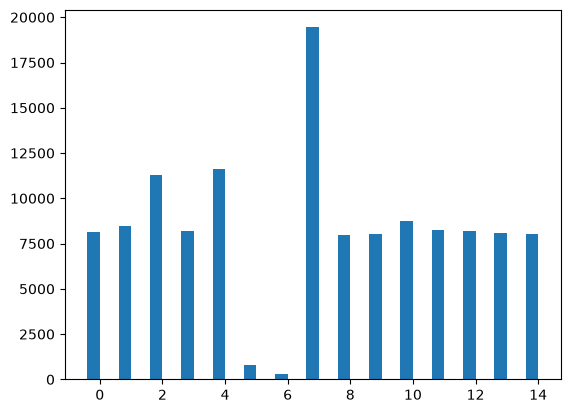

In [115]:
plt.bar(before_smote.index - 0.2, before_smote.values, width=0.4, label="Before SMOTE")

<BarContainer object of 15 artists>

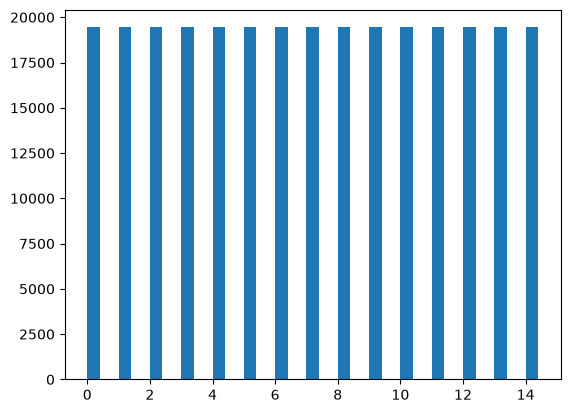

In [116]:
plt.bar(after_smote.index + 0.2, after_smote.values, width=0.4, label="After SMOTE")

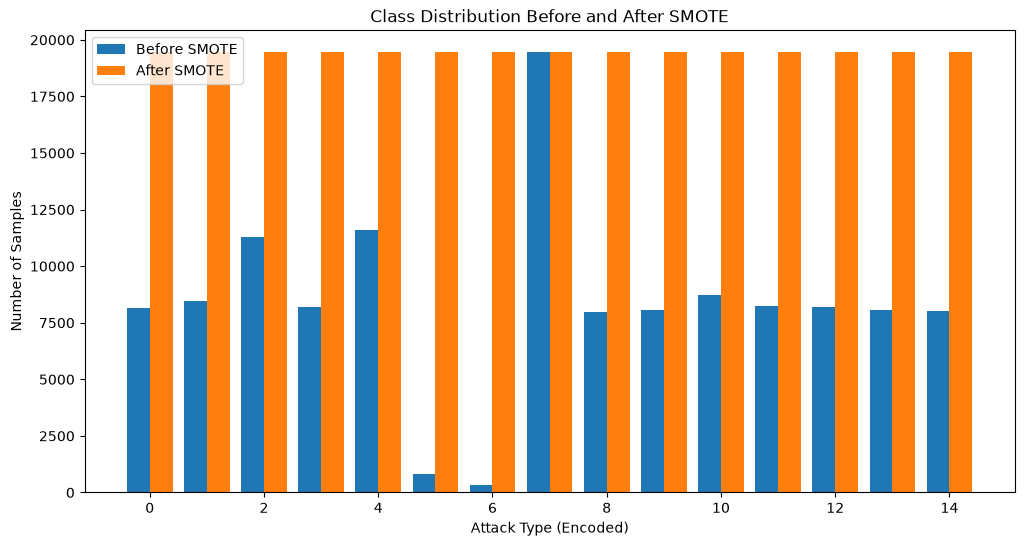

In [117]:
# adding title and axis labels to make the chart clear
plt.figure(figsize=(12,6))
plt.bar(before_smote.index - 0.2, before_smote.values, width=0.4, label="Before SMOTE")
plt.bar(after_smote.index + 0.2, after_smote.values, width=0.4, label="After SMOTE")
plt.title("Class Distribution Before and After SMOTE")
plt.xlabel("Attack Type (Encoded)")
plt.ylabel("Number of Samples")
plt.legend()
plt.show()

## 6. training my three models
random forest first, then svm, then knn, just using the default settings since im still learning how to tune them

In [118]:
from sklearn.ensemble import RandomForestClassifier

In [119]:
random_forest = RandomForestClassifier(random_state=42)

In [120]:
# training random forest on the balanced smote data
random_forest.fit(X_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [121]:
y_prediction_rf = random_forest.predict(X_test)

In [122]:
from sklearn.metrics import classification_report

In [123]:
print(classification_report(y_test, y_prediction_rf))

              precision    recall  f1-score   support

           0       0.97      0.95      0.96      2039
           1       0.82      0.78      0.80      2112
           2       1.00      1.00      1.00      2818
           3       1.00      1.00      1.00      2050
           4       1.00      1.00      1.00      2900
           5       0.64      0.84      0.72       200
           6       1.00      1.00      1.00        80
           7       0.98      0.99      0.98      4860
           8       0.79      0.78      0.79      1998
           9       0.99      0.91      0.95      2014
          10       0.85      0.96      0.90      2185
          11       0.79      0.83      0.81      2062
          12       0.88      0.84      0.86      2054
          13       0.99      0.95      0.97      2015
          14       0.82      0.81      0.81      2011

    accuracy                           0.92     31398
   macro avg       0.90      0.91      0.90     31398
weighted avg       0.92   

In [124]:
# importing standardscaler here because svm needs all features on the same scale, unlike random forest which does not care about scale
from sklearn.preprocessing import StandardScaler

In [125]:
scaler = StandardScaler()

In [126]:
# fitting the scaler on training data only, then scaling it, to avoid data leakage
X_train_scaled = scaler.fit_transform(X_train_smote)

In [127]:
# scaling test data using the same rules learned from training data, not learning new ones
X_test_scaled = scaler.transform(X_test)

In [128]:
 from sklearn.svm import SVC

In [129]:
# creating the svm model, using default settings for speed since dataset is large
support_vector_machine = SVC(random_state=42)

In [130]:
# i am taking a smaller balanced sample of the scaled training data, just for svm, because full dataset is too slow
X_train_svm_sample, _, y_train_svm_sample, _ = train_test_split(X_train_scaled, y_train_smote, train_size=30000, stratify=y_train_smote, random_state=42)

In [131]:
y_train_svm_sample.value_counts()

Attack_type_encoded
10    2000
13    2000
7     2000
4     2000
3     2000
0     2000
9     2000
1     2000
2     2000
6     2000
12    2000
11    2000
8     2000
5     2000
14    2000
Name: count, dtype: int64

In [132]:
# here i am training svm on the smaller sample instead of the full dataset, to keep training time reasonable
support_vector_machine.fit(X_train_svm_sample, y_train_svm_sample)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [133]:
y_prediction_svm = support_vector_machine.predict(X_test_scaled)

In [134]:
print(classification_report(y_test, y_prediction_svm))

              precision    recall  f1-score   support

           0       0.37      0.89      0.52      2039
           1       0.33      0.39      0.36      2112
           2       1.00      0.94      0.97      2818
           3       0.61      0.84      0.71      2050
           4       1.00      0.95      0.98      2900
           5       0.18      0.85      0.29       200
           6       0.99      1.00      0.99        80
           7       0.93      0.42      0.58      4860
           8       0.53      0.16      0.24      1998
           9       0.75      0.47      0.58      2014
          10       0.26      0.25      0.26      2185
          11       0.21      0.49      0.29      2062
          12       0.62      0.07      0.13      2054
          13       0.74      0.84      0.79      2015
          14       0.27      0.14      0.18      2011

    accuracy                           0.54     31398
   macro avg       0.59      0.58      0.52     31398
weighted avg       0.64   

In [135]:
# i am trying a bigger svm sample, 45000 this time, to see if it improves the weak results
X_train_svm_sample2, _, y_train_svm_sample2, _ = train_test_split(X_train_scaled, y_train_smote, train_size=45000, stratify=y_train_smote, random_state=42)

In [136]:
y_train_svm_sample2.value_counts()

Attack_type_encoded
0     3000
5     3000
13    3000
2     3000
1     3000
11    3000
9     3000
14    3000
12    3000
7     3000
3     3000
4     3000
6     3000
8     3000
10    3000
Name: count, dtype: int64

In [137]:
support_vector_machine.fit(X_train_svm_sample2, y_train_svm_sample2)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [138]:
y_prediction_svm2 = support_vector_machine.predict(X_test_scaled)

In [139]:
# checking if the bigger sample actually improved svm results
print(classification_report(y_test, y_prediction_svm2))

              precision    recall  f1-score   support

           0       0.35      0.68      0.46      2039
           1       0.34      0.43      0.38      2112
           2       1.00      0.95      0.97      2818
           3       0.61      0.85      0.71      2050
           4       1.00      0.96      0.98      2900
           5       0.18      0.85      0.30       200
           6       0.99      1.00      0.99        80
           7       0.85      0.48      0.62      4860
           8       0.54      0.15      0.24      1998
           9       0.78      0.48      0.59      2014
          10       0.19      0.25      0.22      2185
          11       0.21      0.49      0.29      2062
          12       0.62      0.07      0.13      2054
          13       0.74      0.84      0.79      2015
          14       0.27      0.08      0.13      2011

    accuracy                           0.54     31398
   macro avg       0.58      0.57      0.52     31398
weighted avg       0.62   

In [140]:
from sklearn.neighbors import KNeighborsClassifier

In [141]:
k_nearest_neighbors = KNeighborsClassifier()

In [142]:
# training knn on the same 30000 row sample we used for svm, since knn is also slow with large data
k_nearest_neighbors.fit(X_train_svm_sample, y_train_svm_sample)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](15,)","[ 0, 1, 2,...,12,13,14]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [143]:
y_prediction_knn = k_nearest_neighbors.predict(X_test_scaled)

In [144]:
print(classification_report(y_test, y_prediction_knn))

              precision    recall  f1-score   support

           0       0.88      0.92      0.90      2039
           1       0.50      0.65      0.56      2112
           2       1.00      0.98      0.99      2818
           3       0.64      0.65      0.64      2050
           4       1.00      1.00      1.00      2900
           5       0.34      0.78      0.47       200
           6       0.96      1.00      0.98        80
           7       0.76      0.73      0.75      4860
           8       0.30      0.30      0.30      1998
           9       0.60      0.66      0.63      2014
          10       0.85      0.84      0.85      2185
          11       0.40      0.39      0.39      2062
          12       0.42      0.30      0.35      2054
          13       0.80      0.82      0.81      2015
          14       0.32      0.27      0.29      2011

    accuracy                           0.68     31398
   macro avg       0.65      0.69      0.66     31398
weighted avg       0.68   

In [145]:
# writing the classification reports to a text file for my report
with open("model_results.txt", "w") as file:
    file.write("Random Forest\n")
    file.write(classification_report(y_test, y_prediction_rf))
    file.write("\n\nSVM (45000 sample)\n")
    file.write(classification_report(y_test, y_prediction_svm2))
    file.write("\n\nKNN (30000 sample)\n")
    file.write(classification_report(y_test, y_prediction_knn))

## 7. confusion matrix and macro f1
checking where each model gets confused and comparing them using macro f1

In [146]:
# i am importing confusion matrix so that i can see exactly which classes get mixed up
from sklearn.metrics import confusion_matrix

In [147]:
cm_rf = confusion_matrix(y_test, y_prediction_rf)

In [148]:
print(cm_rf)

[[1945    0    0    0    0   14    0    0    0    1   79    0    0    0
     0]
 [   0 1657    0    0    0    0    0    7  125    0    0  166   55    7
    95]
 [   0    0 2810    0    0    8    0    0    0    0    0    0    0    0
     0]
 [   0    0    0 2050    0    0    0    0    0    0    0    0    0    0
     0]
 [   0    0    0    0 2900    0    0    0    0    0    0    0    0    0
     0]
 [   1    0    0    0    0  168    0    0    1    3   24    0    3    0
     0]
 [   0    0    0    0    0    0   80    0    0    0    0    0    0    0
     0]
 [   0    2    0    0    0    0    0 4795   15    4   11    0    5    2
    26]
 [   0   74    0    0    0    0    0   68 1561    1    3  151   55    3
    82]
 [   1    0    0    0    0   48    0    0    0 1829  136    0    0    0
     0]
 [  61    1    0    0    0    2    0    0    0    6 2107    0    8    0
     0]
 [   0  131    0    0    0    0    0    0  101    0    3 1711   44    5
    67]
 [   0   52    0    0    0   23    0    

In [149]:
import seaborn as sns

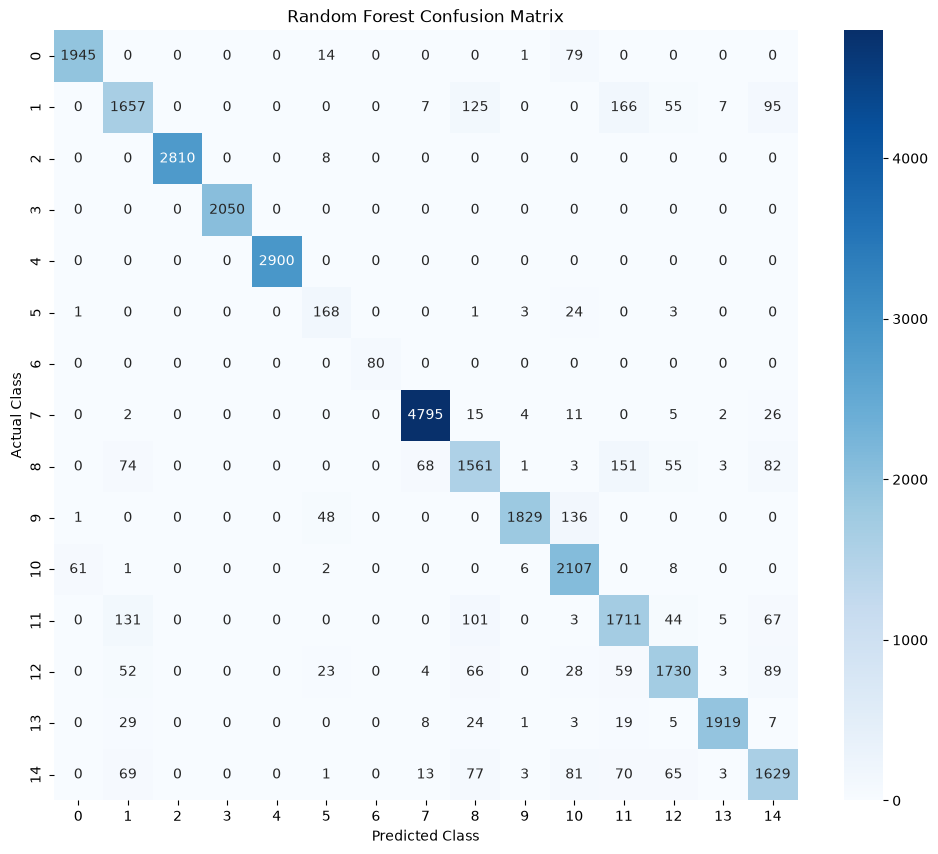

In [150]:
# making a heatmap so its easier to see where random forest gets confused
plt.figure(figsize=(12,10))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [151]:
cm_svm = confusion_matrix(y_test, y_prediction_svm2)
cm_knn = confusion_matrix(y_test, y_prediction_knn)

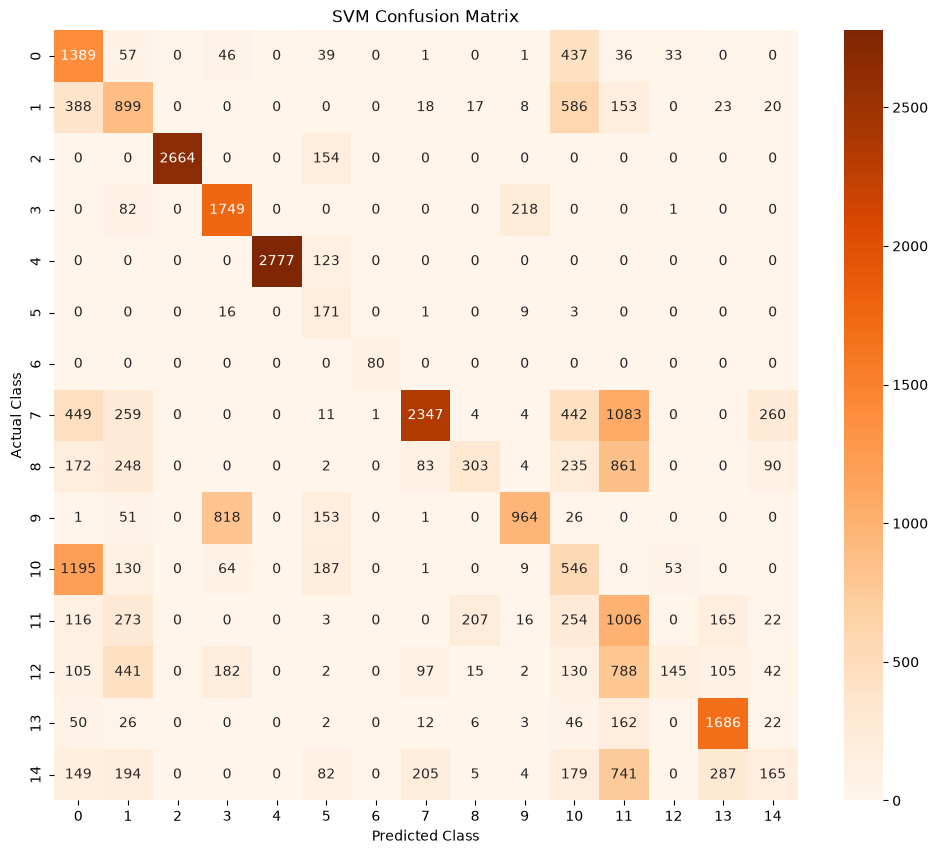

In [152]:
plt.figure(figsize=(12,10))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Oranges")
plt.title("SVM Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

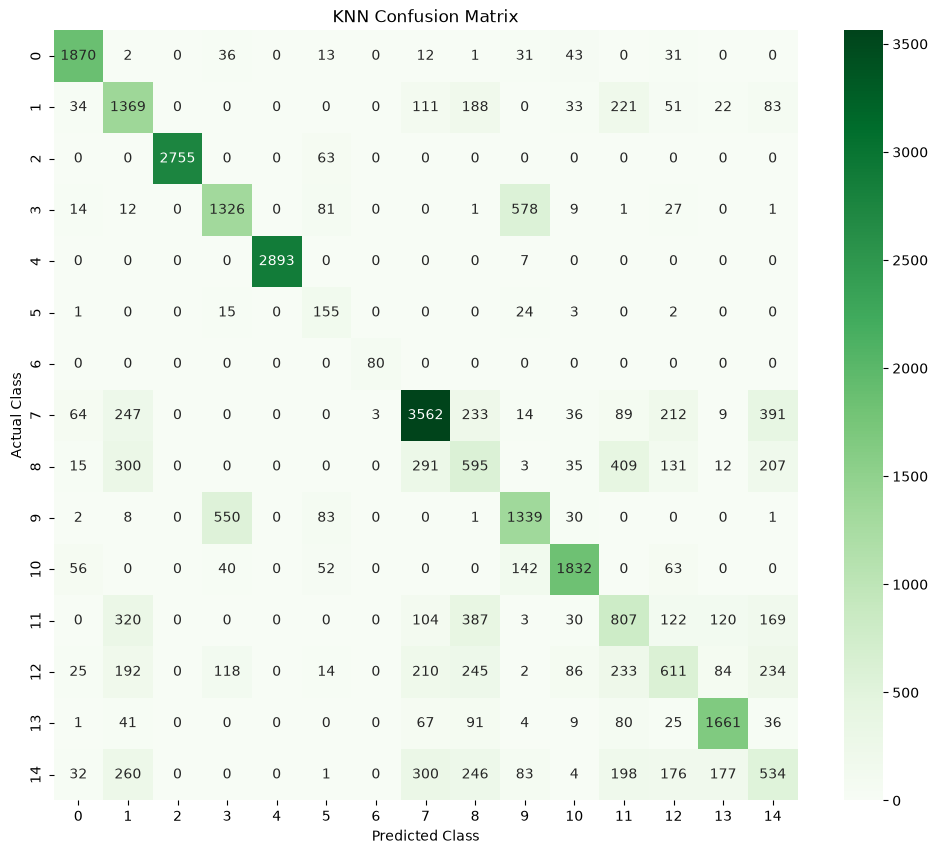

In [153]:
plt.figure(figsize=(12,10))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Greens")
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

In [154]:
# i am now tryiny to importing f1_score so i can pull out just the macro f1 number for each model
from sklearn.metrics import f1_score

In [155]:
f1_rf = f1_score(y_test, y_prediction_rf, average="macro")
f1_svm = f1_score(y_test, y_prediction_svm2, average="macro")
f1_knn = f1_score(y_test, y_prediction_knn, average="macro")

In [156]:
print(f1_rf, f1_svm, f1_knn)

0.9039186947675162 0.5190030117073188 0.6606273796551518


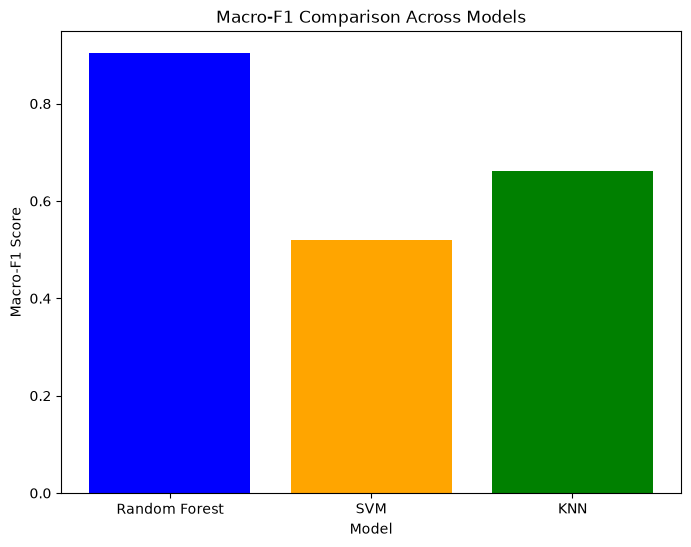

In [157]:
# i am making a bar chart comparing macro f1 across all three models
plt.figure(figsize=(8,6))
plt.bar(["Random Forest", "SVM", "KNN"], [f1_rf, f1_svm, f1_knn], color=["blue", "orange", "green"])
plt.title("Macro-F1 Comparison Across Models")
plt.xlabel("Model")
plt.ylabel("Macro-F1 Score")
plt.show()

## 8. feature importance
checking which features my random forest actually used the most

In [158]:
# i want to see which features random forest actually used the most to make its decisions
# this helps me explain in my report which columns really mattered for detecting attacks
importances = random_forest.feature_importances_

In [159]:
feature_importance_table = pd.DataFrame({"Feature": X.columns, "Importance": importances}).sort_values(by="Importance", ascending=False)
print(feature_importance_table.head(15))

                Feature  Importance
7               tcp.ack    0.161002
14          tcp.dstport    0.145442
18              tcp.seq    0.107610
17              tcp.len    0.102341
8           tcp.ack_raw    0.064161
9          tcp.checksum    0.062833
3           icmp.seq_le    0.056697
20           udp.stream    0.051258
15            tcp.flags    0.049002
2         icmp.checksum    0.030274
11   tcp.connection.rst    0.022660
5   http.content_length    0.022073
21       udp.time_delta    0.016077
19             udp.port    0.012587
6         http.response    0.011061


In [160]:
# i want to see the full list, not just top 15, so i can check where my encoded columns actually rank
print(feature_importance_table)

                                              Feature    Importance
7                                             tcp.ack  1.610018e-01
14                                        tcp.dstport  1.454419e-01
18                                            tcp.seq  1.076096e-01
17                                            tcp.len  1.023409e-01
8                                         tcp.ack_raw  6.416073e-02
..                                                ...           ...
61  http.request.version_Src=javascript:alert('Vul...  1.312056e-06
56  http.request.version_/etc/passwd|?data=Downloa...  8.262799e-07
58                http.request.version_By Dr HTTP/1.1  3.630321e-07
36                                            OPTIONS  3.208568e-07
62                              mqtt.conack.flags_0.0  0.000000e+00

[67 rows x 2 columns]


## 9. checking if feature selection actually helped
comparing my selected features against a version with more columns, just to see if i actually needed to drop them

In [161]:
# loading the dataset from before feature selection happened, so i can compare it against my selected features version
# i am keeping this separate from my main df so i dont overwrite all the work i already did
df_full_features = pd.read_csv("ML-EdgeIIoT-cleaned.csv")

C:\Users\user\AppData\Local\Temp\ipykernel_24460\710617053.py:3: DtypeWarning: Columns (0: arp.dst.proto_ipv4, 1: arp.src.proto_ipv4, 2: http.file_data, 3: http.request.uri.query, 4: http.request.method, 5: http.referer, 6: http.request.full_uri, 7: http.request.version, 8: tcp.options, 9: tcp.payload, 10: tcp.srcport, 11: dns.qry.name.len, 12: mqtt.conack.flags, 13: mqtt.msg, 14: mqtt.protoname, 15: mqtt.topic) have mixed types. Specify dtype option on import or set low_memory=False.
  df_full_features = pd.read_csv("ML-EdgeIIoT-cleaned.csv")


In [162]:
df_full_features.shape

(156986, 55)

In [163]:
# removing the 4 columns that had real data errors, and using the same steps i already know work
df_full_features = df_full_features.drop(columns=["frame.time", "ip.src_host", "ip.dst_host", "tcp.srcport"])

In [164]:
df_full_features.shape

(156986, 51)

In [165]:
messy_columns_full = ["arp.dst.proto_ipv4", "arp.src.proto_ipv4", "http.referer", "http.request.version", "mqtt.conack.flags", "mqtt.protoname", "mqtt.topic", "http.request.method", "http.request.uri.query", "http.request.full_uri", "tcp.payload", "tcp.options", "mqtt.msg", "http.file_data"]
for col in messy_columns_full:
    df_full_features[col] = df_full_features[col].astype(str)
    df_full_features[col] = df_full_features[col].replace(["0", "0.0.0.0", "0x00000000"], "0.0")

In [166]:
# only encoding the small safe columns this time, leaving out the ones that caused memory error because they have too many unique values
messy_columns_full_safe = ["arp.dst.proto_ipv4", "arp.src.proto_ipv4", "http.referer", "http.request.version", "mqtt.conack.flags", "mqtt.protoname", "mqtt.topic", "http.request.method"]
df_full_features = pd.get_dummies(df_full_features, columns=messy_columns_full_safe, drop_first=False)

In [167]:
df_full_features.shape

(156986, 76)

In [168]:
df_full_features = df_full_features.drop(columns=["http.request.uri.query", "http.request.full_uri", "tcp.payload", "tcp.options", "mqtt.msg", "http.file_data"])

In [169]:
# adding the same encoded target column i already made earlier, using the same label encoder so the numbers match exactly
df_full_features["Attack_type_encoded"] = label_encoder.transform(df_full_features["Attack_type"])

In [170]:
df_full_features.shape

(156986, 71)

In [171]:
X_full = df_full_features.drop(columns=["Attack_type", "Attack_type_encoded"])
y_full = df_full_features["Attack_type_encoded"]

In [172]:
print(X_full.shape)
print(y_full.shape)

(156986, 69)
(156986,)


In [173]:
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(X_full, y_full, test_size=0.2, stratify=y_full, random_state=42)

In [174]:
# dropping dns.qry.name.len here too, i forgot this one earlier, its mostly placeholder text and caused an error
df_full_features = df_full_features.drop(columns=["dns.qry.name.len"])

In [175]:
X_full = df_full_features.drop(columns=["Attack_type", "Attack_type_encoded"])
y_full = df_full_features["Attack_type_encoded"]

In [176]:
X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(X_full, y_full, test_size=0.2, stratify=y_full, random_state=42)

In [177]:
# applying smote again now that the error is fixed
smote_full = SMOTE(random_state=42)
X_train_full_smote, y_train_full_smote = smote_full.fit_resample(X_train_full, y_train_full)

In [178]:
print(X_train_full_smote.shape)
print(y_train_full_smote.value_counts())

(291615, 68)
Attack_type_encoded
12    19441
1     19441
8     19441
11    19441
0     19441
10    19441
14    19441
7     19441
13    19441
2     19441
9     19441
3     19441
4     19441
5     19441
6     19441
Name: count, dtype: int64


In [179]:
# training a new random forest on the full features version, using the same settings as before so the comparison is fair
random_forest_full = RandomForestClassifier(random_state=42)
random_forest_full.fit(X_train_full_smote, y_train_full_smote)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [180]:
y_prediction_rf_full = random_forest_full.predict(X_test_full)

In [181]:
print(classification_report(y_test_full, y_prediction_rf_full))

              precision    recall  f1-score   support

           0       0.97      0.95      0.96      2039
           1       0.82      0.79      0.80      2112
           2       1.00      1.00      1.00      2818
           3       1.00      1.00      1.00      2050
           4       1.00      1.00      1.00      2900
           5       0.63      0.84      0.72       200
           6       1.00      1.00      1.00        80
           7       1.00      1.00      1.00      4860
           8       0.79      0.81      0.80      1998
           9       0.99      0.91      0.95      2014
          10       0.85      0.96      0.91      2185
          11       0.79      0.83      0.81      2062
          12       0.88      0.84      0.86      2054
          13       0.99      0.95      0.97      2015
          14       0.83      0.81      0.82      2011

    accuracy                           0.92     31398
   macro avg       0.90      0.91      0.91     31398
weighted avg       0.93   

In [182]:
f1_rf_selected = f1_score(y_test, y_prediction_rf, average="macro")
f1_rf_full = f1_score(y_test_full, y_prediction_rf_full, average="macro")

In [183]:
print(f1_rf_selected, f1_rf_full)

0.9039186947675162 0.906386120375146


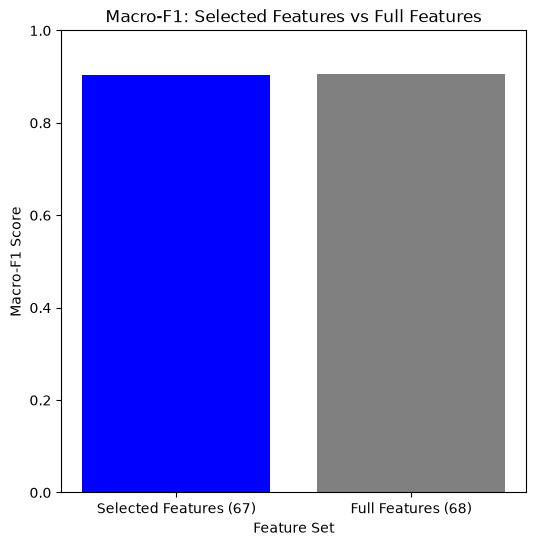

In [184]:
# small bar chart comparing selected features vs full features, to show feature selection did not hurt performance
plt.figure(figsize=(6,6))
plt.bar(["Selected Features (67)", "Full Features (68)"], [f1_rf_selected, f1_rf_full], color=["blue", "gray"])
plt.title("Macro-F1: Selected Features vs Full Features")
plt.xlabel("Feature Set")
plt.ylabel("Macro-F1 Score")
plt.ylim(0, 1)
plt.show()

## 10. pr-auc for mitm and fingerprinting
looking closer at my two rare classes using pr-auc instead of accuracy

In [185]:
from sklearn.metrics import precision_recall_curve, auc

In [186]:
y_prob_rf = random_forest.predict_proba(X_test)
y_prob_knn = k_nearest_neighbors.predict_proba(X_test_scaled)

In [187]:
# calculating pr-auc for each class separately, then i can average them like macro f1 does
pr_auc_rf_per_class = []
for i in range(15):
    precision, recall, thresholds = precision_recall_curve(y_test == i, y_prob_rf[:, i])
    pr_auc_rf_per_class.append(auc(recall, precision))

In [188]:
pr_auc_knn_per_class = []
for i in range(15):
    precision, recall, thresholds = precision_recall_curve(y_test == i, y_prob_knn[:, i])
    pr_auc_knn_per_class.append(auc(recall, precision))

In [189]:
import numpy as np
print("Random Forest PR-AUC:", np.mean(pr_auc_rf_per_class))
print("KNN PR-AUC:", np.mean(pr_auc_knn_per_class))

Random Forest PR-AUC: 0.9504436478143506
KNN PR-AUC: 0.7188431331737315


In [190]:
# checking pr-auc specifically for mitm and fingerprinting, my rare classes
print("Random Forest - MITM PR-AUC:", pr_auc_rf_per_class[6])
print("Random Forest - Fingerprinting PR-AUC:", pr_auc_rf_per_class[5])
print("KNN - MITM PR-AUC:", pr_auc_knn_per_class[6])
print("KNN - Fingerprinting PR-AUC:", pr_auc_knn_per_class[5])

Random Forest - MITM PR-AUC: 1.0
Random Forest - Fingerprinting PR-AUC: 0.863156948874978
KNN - MITM PR-AUC: 0.9878048780487805
KNN - Fingerprinting PR-AUC: 0.6931796295562103


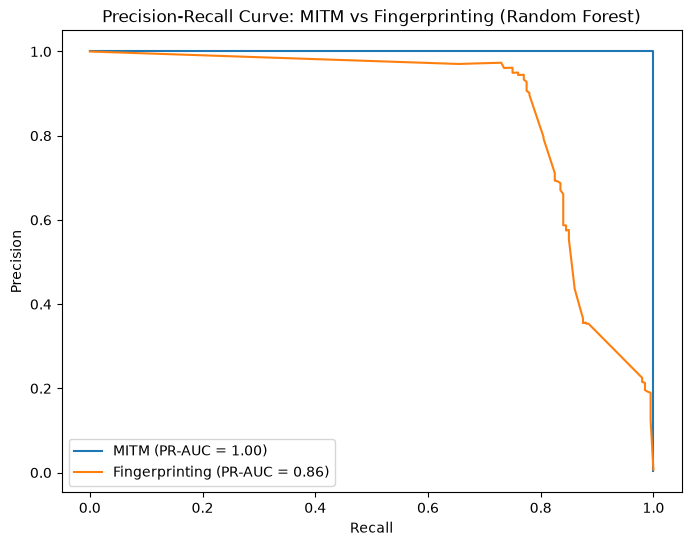

In [191]:
# plotting the actual precision recall curve for mitm and fingerprinting, to show the pr-auc difference visually
precision_mitm, recall_mitm, _ = precision_recall_curve(y_test == 6, y_prob_rf[:, 6])
precision_fingerprinting, recall_fingerprinting, _ = precision_recall_curve(y_test == 5, y_prob_rf[:, 5])

plt.figure(figsize=(8,6))
plt.plot(recall_mitm, precision_mitm, label="MITM (PR-AUC = 1.00)")
plt.plot(recall_fingerprinting, precision_fingerprinting, label="Fingerprinting (PR-AUC = 0.86)")
plt.title("Precision-Recall Curve: MITM vs Fingerprinting (Random Forest)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

## 11. looking at my mistakes
pulling out the fingerprinting rows my model got wrong to try understand why

In [192]:
misclassified_fingerprinting = X_test[(y_test == 5) & (y_prediction_rf != 5)]

In [193]:
print(misclassified_fingerprinting.shape)

(32, 67)


In [194]:
misclassified_fingerprinting[["tcp.ack", "tcp.dstport", "tcp.seq", "tcp.len"]].describe()

,tcp.ack,tcp.dstport,tcp.seq,tcp.len
count,32.000000,32.000000,32.000000,32.0
mean,0.218750,6608.000000,0.218750,0.0
std,0.420013,17261.503048,0.420013,0.0
min,0.000000,0.000000,0.000000,0.0
25%,0.000000,0.000000,0.000000,0.0
50%,0.000000,0.000000,0.000000,0.0
75%,0.000000,0.000000,0.000000,0.0
max,1.000000,60294.000000,1.000000,0.0


In [195]:
# checking the correctly classified fingerprinting rows too, to compare against the misclassified ones
correctly_classified_fingerprinting = X_test[(y_test == 5) & (y_prediction_rf == 5)]
correctly_classified_fingerprinting[["tcp.ack", "tcp.dstport", "tcp.seq", "tcp.len"]].describe()

,tcp.ack,tcp.dstport,tcp.seq,tcp.len
count,168.000000,168.000000,168.000000,168.0
mean,0.107143,11194.196429,0.107143,0.0
std,0.310219,23038.857436,0.310219,0.0
min,0.000000,0.000000,0.000000,0.0
25%,0.000000,0.000000,0.000000,0.0
50%,0.000000,0.000000,0.000000,0.0
75%,0.000000,0.000000,0.000000,0.0
max,1.000000,65535.000000,1.000000,0.0


In [196]:
# checking what these misclassified fingerprinting rows actually got predicted as, to connect this back to the confusion matrix pattern
misclassified_predictions = y_prediction_rf[(y_test == 5) & (y_prediction_rf != 5)]
pd.Series(misclassified_predictions).value_counts()

10    24
9      3
12     3
8      1
0      1
Name: count, dtype: int64

In [197]:
len(y_test)

31398

## 12. my baseline
checking what i would get if i just guessed normal every time, so i can prove my real models are actually doing something

In [198]:
baseline_predictions = [7] * len(y_test)

In [199]:
print(classification_report(y_test, baseline_predictions))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00      2039
           1       0.00      0.00      0.00      2112
           2       0.00      0.00      0.00      2818
           3       0.00      0.00      0.00      2050
           4       0.00      0.00      0.00      2900
           5       0.00      0.00      0.00       200
           6       0.00      0.00      0.00        80
           7       0.15      1.00      0.27      4860
           8       0.00      0.00      0.00      1998
           9       0.00      0.00      0.00      2014
          10       0.00      0.00      0.00      2185
          11       0.00      0.00      0.00      2062
          12       0.00      0.00      0.00      2054
          13       0.00      0.00      0.00      2015
          14       0.00      0.00      0.00      2011

    accuracy                           0.15     31398
   macro avg       0.01      0.07      0.02     31398
weighted avg       0.02   

c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

In [200]:
# adding the baseline results to my saved results file too
with open("model_results.txt", "a") as file:
    file.write("\n\nBaseline (always predict Normal)\n")
    file.write(classification_report(y_test, baseline_predictions))

c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

In [201]:
with open("model_results.txt", "r") as file:
    print(file.read())

Random Forest
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      2039
           1       0.82      0.78      0.80      2112
           2       1.00      1.00      1.00      2818
           3       1.00      1.00      1.00      2050
           4       1.00      1.00      1.00      2900
           5       0.64      0.84      0.72       200
           6       1.00      1.00      1.00        80
           7       0.98      0.99      0.98      4860
           8       0.79      0.78      0.79      1998
           9       0.99      0.91      0.95      2014
          10       0.85      0.96      0.90      2185
          11       0.79      0.83      0.81      2062
          12       0.88      0.84      0.86      2054
          13       0.99      0.95      0.97      2015
          14       0.82      0.81      0.81      2011

    accuracy                           0.92     31398
   macro avg       0.90      0.91      0.90     31398
weighted avg